# Bird species classification: supervised CNN

Train a small CNN directly on the 100 labelled clips, then predict the species of the 100 test clips.

In [1]:
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from pathlib import Path
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

DATA_DIR = Path("data")
SR = 32000
N_MELS = 64
N_FRAMES = 312

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## Loading the data

Each clip is turned into a log-mel spectrogram of shape (64 mel bands × 312 time frames), scaled to lie between 0 and 1.

In [2]:
AUDIO_EXTS = {".wav", ".flac", ".ogg", ".mp3"}


def load_mel(path):
    y, _ = librosa.load(path, sr=SR, duration=5.0)
    y = np.pad(y, (0, max(0, 5 * SR - len(y))))
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=1024, hop_length=512, n_mels=N_MELS, fmin=50, fmax=14000)
    mel = librosa.power_to_db(mel, ref=np.max, top_db=80)
    return (mel[:, :N_FRAMES] / 80 + 1).astype(np.float32)


def load_files(paths):
    return np.stack(Parallel(n_jobs=8)(delayed(load_mel)(p) for p in paths))


def audio_files(folder):
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in AUDIO_EXTS)

In [3]:
labels = pd.read_csv(DATA_DIR / "labelled" / "labels.csv")
classes = sorted(labels.species.unique())
X_lab = load_files([DATA_DIR / "labelled" / f for f in labels.filename])
y_lab = labels.species.map({c: i for i, c in enumerate(classes)}).values

print(X_lab.shape)
labels.species.value_counts()

(100, 64, 312)


species
Eurasian Wren     66
Song Thrush       19
European Robin    15
Name: count, dtype: int64

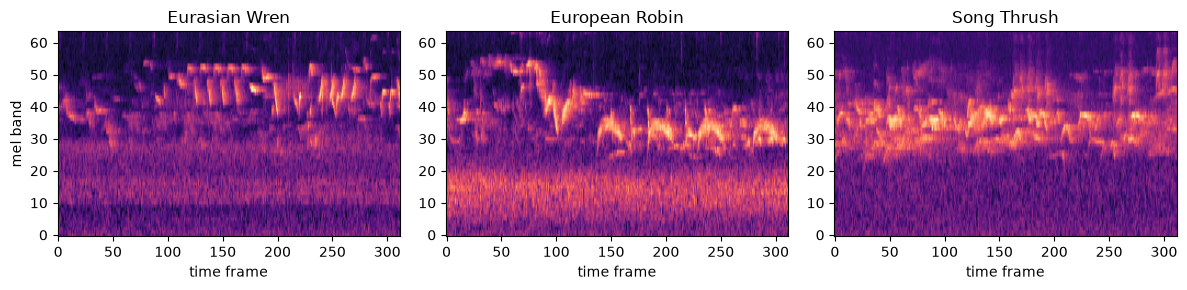

In [4]:
fig, axes = plt.subplots(1, len(classes), figsize=(4 * len(classes), 3))
for ax, c in zip(axes, range(len(classes))):
    ax.imshow(X_lab[y_lab == c][0], origin="lower", aspect="auto", cmap="magma")
    ax.set_title(classes[c])
    ax.set_xlabel("time frame")
axes[0].set_ylabel("mel band")
plt.tight_layout()

Hold out 20% of the labelled clips so we can see how well the model generalises.

In [5]:
X_train, X_val, y_train, y_val = train_test_split(X_lab, y_lab, test_size=0.2, stratify=y_lab, random_state=0)
len(X_train), len(X_val)

(80, 20)

In [6]:
train_loader = DataLoader(TensorDataset(torch.tensor(X_train).unsqueeze(1), torch.tensor(y_train)), batch_size=16, shuffle=True)
X_val_t = torch.tensor(X_val).unsqueeze(1).to(device)
y_val_t = torch.tensor(y_val).to(device)

## Model

In [7]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(1, 16),
            conv_block(16, 32),
            conv_block(32, 64),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
        )
        self.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(64, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


model = SmallCNN(len(classes)).to(device)
sum(p.numel() for p in model.parameters())

23715

## Training

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
n_epochs = 50

train_losses, val_losses, val_accs = [], [], []
for epoch in range(n_epochs):
    model.train()
    total = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    train_losses.append(total / len(train_loader.dataset))

    model.eval()
    with torch.no_grad():
        logits = model(X_val_t)
        val_losses.append(loss_fn(logits, y_val_t).item())
        val_accs.append((logits.argmax(1) == y_val_t).float().mean().item())

    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch + 1}: train loss {train_losses[-1]:.3f}, val loss {val_losses[-1]:.3f}, val acc {val_accs[-1]:.2f}")

epoch 10: train loss 0.795, val loss 1.069, val acc 0.40
epoch 20: train loss 0.699, val loss 0.934, val acc 0.65
epoch 30: train loss 0.653, val loss 0.933, val acc 0.55
epoch 40: train loss 0.629, val loss 0.965, val acc 0.65
epoch 50: train loss 0.576, val loss 1.057, val acc 0.65


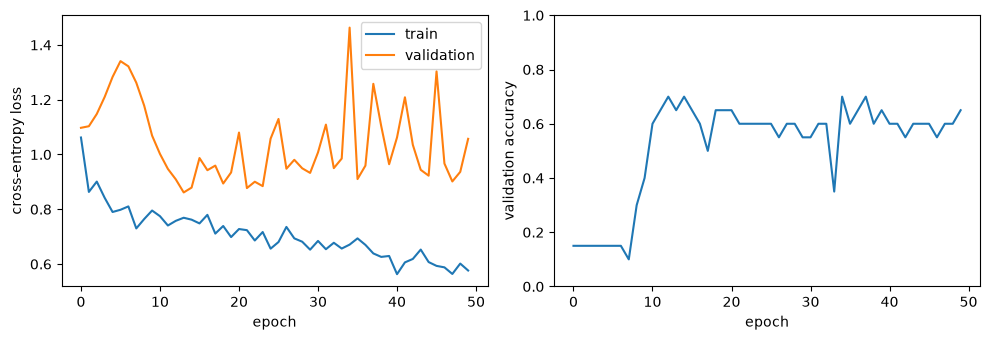

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(train_losses, label="train")
ax1.plot(val_losses, label="validation")
ax1.set_xlabel("epoch")
ax1.set_ylabel("cross-entropy loss")
ax1.legend()
ax2.plot(val_accs)
ax2.set_xlabel("epoch")
ax2.set_ylabel("validation accuracy")
ax2.set_ylim(0, 1)
plt.tight_layout()

## Predicting on the test set

Run your model on the 100 unlabelled test clips. Put your group name in the cell below before saving — the cell will not run without it.

In [10]:
test_paths = audio_files(DATA_DIR / "test")
test_files = [p.name for p in test_paths]
X_test = load_files(test_paths)
X_test.shape

(100, 64, 312)

In [11]:
model.eval()
with torch.no_grad():
    test_preds = model(torch.tensor(X_test).unsqueeze(1).to(device)).argmax(1).cpu().numpy()

pd.Series([classes[i] for i in test_preds]).value_counts()

Eurasian Wren     79
Song Thrush       16
European Robin     5
Name: count, dtype: int64

In [13]:
GROUP_NAME = ''

group = GROUP_NAME.strip().replace(" ", "_")
out_dir = Path("test_results")
out_dir.mkdir(exist_ok=True)
out_path = out_dir / f"{group}_supervised.csv"

results = pd.DataFrame({
    "filename": test_files,
    "species": [classes[i] for i in test_preds],
    "model": "supervised",
    "group": GROUP_NAME.strip(),
})
results.to_csv(out_path, index=False)
print(f"Saved {len(results)} predictions to {out_path}")
results.head()

Saved 100 predictions to test_results/Danny_organiser_supervised.csv


,filename,species,model,group
0,A4_20250306_175100_c2.wav,Eurasian Wren,supervised,Danny_organiser
1,A5_20250511_032600_c1.wav,Eurasian Wren,supervised,Danny_organiser
2,B5_20250317_055400_c3.wav,European Robin,supervised,Danny_organiser
3,C3_20250306_060300_c2.wav,Eurasian Wren,supervised,Danny_organiser
4,C3_20250308_074900_c11.wav,Eurasian Wren,supervised,Danny_organiser
